# Análisis de Árboles de Decisión – Implementación y Aplicación en el Entorno Laboral

**Integrante: CUSSI NICOLÁS A.**

En este trabajo implementaremos un modelo de Árbol de Decisión utilizando el dataset `penguins` de seaborn. Se explicará el código paso a paso, se analizarán las decisiones tomadas por el árbol, se propondrá una aplicación realista en un contexto laboral, y se reflexionará sobre las ventajas de este tipo de modelos frente a otros más complejos.


### Paso 1: Carga de Librerías

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


### Paso 2: Carga y Preparación de los Datos

In [3]:
# Cargar dataset
df = sns.load_dataset('penguins').dropna()
# Seleccionar características
X = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']]
y = df['species']
# Dividir en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


### Paso 3: Entrenamiento del Árbol de Decisión

In [4]:
# Crear y entrenar el modelo
tree = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
tree.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=4, random_state=42)

### Paso 4: Visualización del Árbol

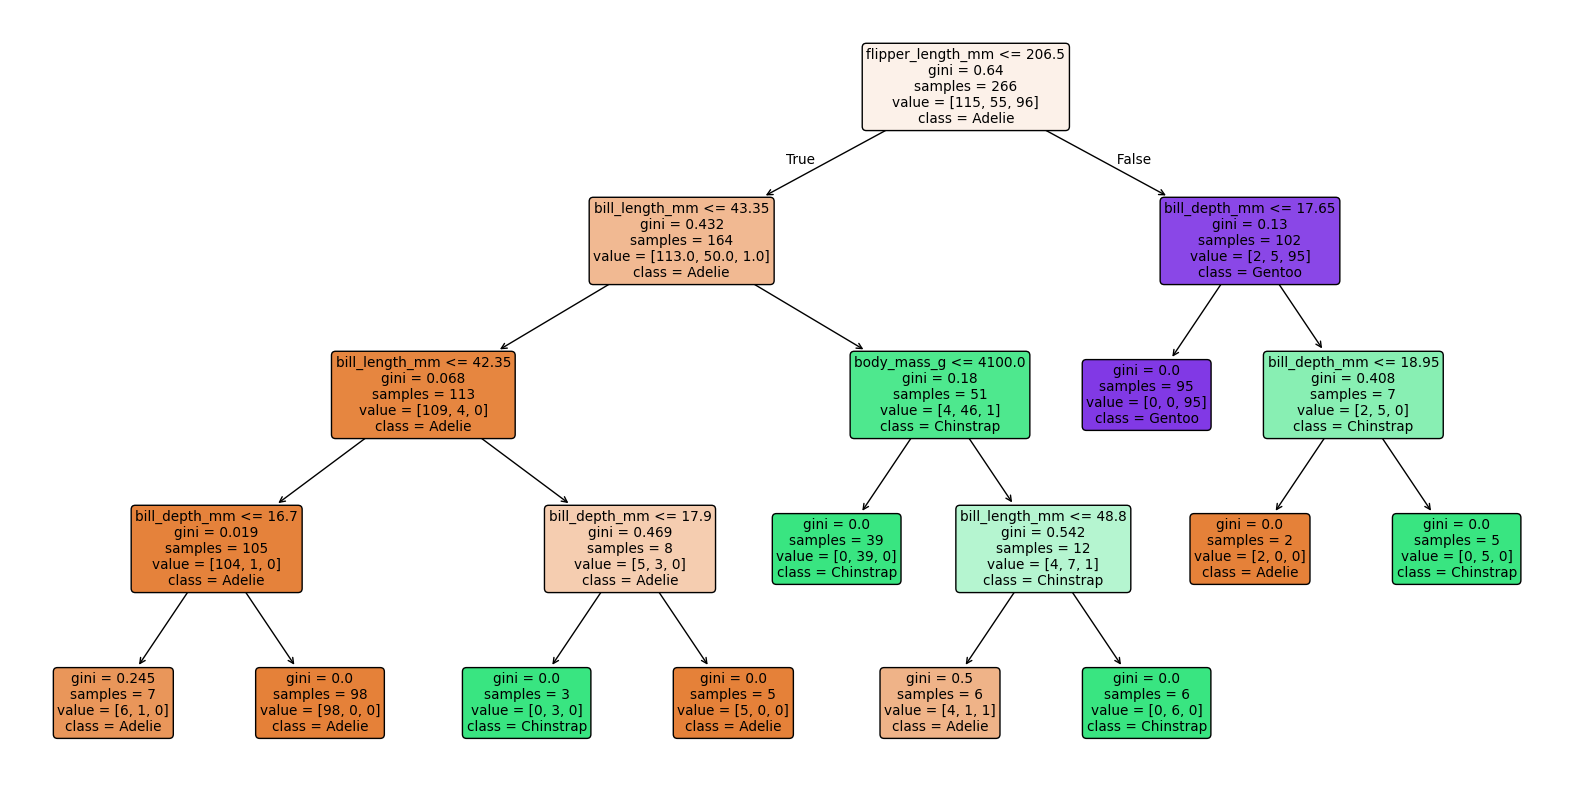

In [5]:
plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=X.columns, class_names=tree.classes_, filled=True, rounded=True)
plt.show()


### Paso 5: Evaluación del Modelo

In [6]:
# Predicciones
y_pred = tree.predict(X_test)
# Métricas
print("Precisión:", accuracy_score(y_test, y_pred))
print("\nMatriz de Confusión:\n", confusion_matrix(y_test, y_pred))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred))


Precisión: 0.9850746268656716

Matriz de Confusión:
 [[30  1  0]
 [ 0 13  0]
 [ 0  0 23]]

Reporte de Clasificación:
               precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        31
   Chinstrap       0.93      1.00      0.96        13
      Gentoo       1.00      1.00      1.00        23

    accuracy                           0.99        67
   macro avg       0.98      0.99      0.98        67
weighted avg       0.99      0.99      0.99        67



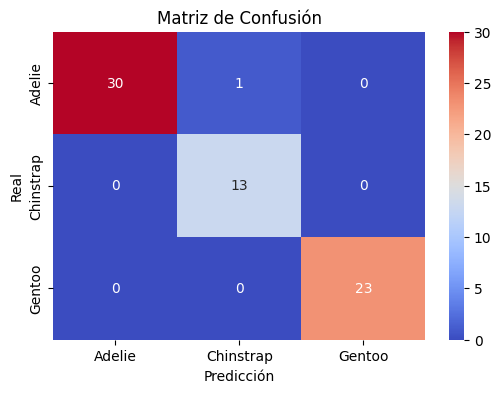

In [7]:

# Visualizar la Matriz de confusión con un mapa de calor
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="coolwarm",
            xticklabels=y.unique(), yticklabels=y.unique())
plt.title("Matriz de Confusión")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()


### Análisis del Árbol
- **Profundidad del Árbol**: Se limita a 4 niveles para evitar sobreajuste.
- **Cantidad de Nodos**: Se genera un árbol binario en donde cada nodo representa una condición sobre las variables.

El árbol divide los datos en función de las variables más importantes para la clasificación de especies de pingüinos. Esto facilita una interpretación clara de cómo se toman las decisiones en cada nivel.


### Aplicación en el Entorno Laboral
Un modelo de Árbol de Decisión como este puede aplicarse en un entorno de **investigación biológica** o **conservación de especies**. Por ejemplo, un biólogo podría clasificar automáticamente una especie de pingüino a partir de mediciones morfológicas (longitud del pico, longitud de la aleta, masa corporal), facilitando tareas de identificación en campo sin necesidad de análisis genéticos costosos y demorados.

También podría ser utilizado en procesos educativos, para enseñar a estudiantes de biología o ecología sobre técnicas de clasificación supervisada.


### Reflexión Personal
Los árboles de decisión presentan una gran ventaja frente a modelos más complejos como los ensambles o las redes neuronales, principalmente por su **interpretabilidad**. La capacidad de visualizar las reglas de decisión facilita su uso en entornos donde es importante justificar las predicciones.

Sin embargo, también presentan limitaciones como la tendencia al **sobreajuste** si no se limitan parámetros como la profundidad. Modelos más complejos como Random Forest o Boosting suelen tener mejor rendimiento en problemas más grandes, pero sacrifican interpretabilidad.
